<a href="https://colab.research.google.com/github/cindyhoo/sogang_ai_data_analysis_detection_model/blob/main/cifar100_cnn_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-100 이미지 분류 CNN 학습 (Google Colab)

Keras 공식 예제 **[Image classification from scratch](https://keras.io/examples/vision/image_classification_from_scratch/)** 의 모델(작은 Xception 구조)을 32×32 이미지에 맞게 줄이고, **[CIFAR-100](https://keras.io/api/datasets/cifar100/)** 으로 처음부터 학습·평가합니다.
로컬 웹 UI(PoC)의 학습 코드와 모델·기본 설정이 같아서, 여기서 학습한 모델을 웹 UI로 가져가 평가·웹캠 테스트에 쓸 수도 있습니다 (§13).

> **검출(detection)이 아니라 분류(classification) 모델입니다.**
> CIFAR-100은 이미지 한 장에 정답 이름 하나만 붙어 있고, 물체가 사진의 어디에 있는지(bounding box) 정보는 없습니다.
> 그래서 이 모델은 "이 사진이 무엇인가"를 맞히는 이미지 분류 모델입니다. 사진 속 여러 물체의 위치까지 찾는 검출 모델을 만들려면 COCO·Pascal VOC처럼 위치 정보가 있는 데이터셋이 필요합니다.

### 실행 방법
1. [Google Colab](https://colab.research.google.com)에서 **파일 → 노트북 업로드**로 이 파일을 엽니다.
2. **런타임 → 런타임 유형 변경**에서 하드웨어 가속기가 **T4 GPU**인지 확인합니다 (이 노트북은 GPU를 요청하도록 저장되어 있습니다).
3. **런타임 → 모두 실행**을 누릅니다. 처음에 CIFAR-100(약 161MB)을 내려받습니다.
4. 학습이 끝나면 §13에서 모델 파일(zip)을 내려받습니다.

**걸리는 시간:** 첫 epoch가 끝나면 전체 예상 시간이 출력됩니다. 참고로 같은 설정(width 1.0, 전체 데이터)이 M2 MacBook GPU에서는 epoch당 약 2분 13초, 25 epoch에 약 56분 걸렸습니다.
먼저 빠르게 돌려 보려면 §1에서 `TRAIN_SUBSET`을 0.1로, `EPOCHS`를 3으로 바꾸세요.

> Colab은 오래 자리를 비우거나 사용량이 많으면 연결이 끊길 수 있고, 끊기면 학습 결과가 사라집니다. 긴 학습은 §1의 `SAVE_TO_DRIVE`를 켜서 결과를 Google Drive에 저장하세요.

| § | 내용 | § | 내용 |
|---|---|---|---|
| 0 | 실행 환경 확인 | 7 | 학습 |
| 1 | 학습 설정 | 8 | 학습 곡선 |
| 2 | 데이터 불러오기 | 9 | test 평가 |
| 3 | 데이터 살펴보기 | 10 | 클래스별 분석 |
| 4 | 데이터 증강 | 11 | 틀린 예측과 확신도 |
| 5 | 입력 파이프라인 (tf.data) | 12 | 이미지 한 장 예측하기 (웹캠) |
| 6 | 모델 만들기 | 13 | 저장·내려받기 (웹 UI로 가져가기) |

## 0. 실행 환경 확인
TensorFlow·Keras 버전과 GPU가 잡혔는지 확인합니다. Colab에는 필요한 패키지가 모두 설치되어 있어 따로 설치할 것은 없습니다.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")   # tf.data를 쓰므로 TensorFlow 백엔드로 실행합니다.

import glob, json, pickle, platform, shutil, time
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator, PercentFormatter
import tensorflow as tf
import keras
from keras import layers

assert keras.__version__.startswith("3."), f"Keras 3이 필요합니다 (현재 {keras.__version__})"
assert keras.backend.backend() == "tensorflow", "KERAS_BACKEND=tensorflow로 설정하고 런타임을 다시 시작하세요."

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

GPUS = tf.config.list_physical_devices("GPU")
GPU_NAME = None
if GPUS:
    try:
        GPU_NAME = tf.config.experimental.get_device_details(GPUS[0]).get("device_name")
    except Exception:
        pass
DEVICE = f"GPU ({GPU_NAME})" if GPU_NAME else ("GPU" if GPUS else "CPU")
SEOUL = ZoneInfo("Asia/Seoul")   # 웹 UI의 모델 ID·시간 표기와 맞춥니다.

print(f"실행 위치: {'Google Colab' if IN_COLAB else '로컬 Jupyter'}")
print(f"Python {platform.python_version()} · TensorFlow {tf.__version__} · Keras {keras.__version__}")
print(f"학습 장치: {DEVICE}")
if not GPUS:
    print("⚠️ GPU가 없습니다. '런타임 → 런타임 유형 변경'에서 T4 GPU를 고르면 훨씬 빠릅니다 (CPU로도 실행은 됩니다).")

# 그래프 모양: 얇은 선, 옅은 격자, 위·오른쪽 테두리 없음. 파랑 = 학습, 주황 = 검증.
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
    "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
})
C_TRAIN, C_VAL, C_GRAY, C_INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
C_GOOD, C_BAD = "#0ca30c", "#d03b3b"
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

실행 위치: Google Colab
Python 3.13.16 · TensorFlow 2.21.0 · Keras 3.13.2
학습 장치: GPU (Tesla T4)


## 1. 학습 설정
기본값은 로컬 웹 UI의 기본값과 같습니다 (같은 `SEED`면 학습/검증 나누기도 똑같습니다). Colab에서는 셀 오른쪽 입력란으로 바꿀 수 있으며, 바꾼 뒤에는 **이 셀부터 다시 실행**하세요.

| 설정 | 기본값 | 뜻 |
|---|---|---|
| `LABEL_MODE` | fine | fine은 사물 100종(예: apple, pear)을, coarse는 이를 묶은 상위 범주 20종(예: fruit_and_vegetables)을 맞힙니다. 이미지는 같고 정답의 단위만 다릅니다. |
| `WIDTH` | 1.0 | 모델의 크기(필터 수 배율)입니다. 클수록 더 세밀한 특징을 배우지만 느려집니다. 0.5 / 0.75 / 1.0일 때 파라미터 약 0.33M / 0.69M / 1.19M입니다. |
| `EPOCHS` | 25 | 학습 이미지 전체를 몇 번 반복해서 볼지 정합니다. 늘릴수록 정확도가 오르다가 어느 순간 더 오르지 않습니다. 시간은 횟수에 비례합니다. |
| `BATCH_SIZE` | 128 | 모델이 한 번 고치기 전에 함께 보는 이미지 수입니다. 크면 1회 반복이 빨라지지만 GPU 메모리를 더 씁니다. |
| `LEARNING_RATE` | 0.0003 | 모델을 한 번 고칠 때 얼마나 크게 바꿀지(보폭)입니다. 너무 크면 학습이 불안정해지고, 너무 작으면 느리게 배웁니다. 원본 예제와 같은 값입니다. |
| `DROPOUT` | 0.25 | 학습 중 분류 직전 단계의 신호 일부(0.25 = 25%)를 무작위로 끕니다. 모델이 학습 이미지를 외워 버리는 과적합을 줄여 줍니다. 0이면 쓰지 않습니다. |
| `AUG_FLIP` · `AUG_ROTATION` · `AUG_TRANSLATION` | 켬 · 켬 · 끔 | 학습 이미지를 매번 조금씩 바꿔 보여 줘서, 모양이 조금 달라도 알아보게 만듭니다 (§4). 원본 예제는 flip과 rotation을 씁니다. |
| `VAL_SPLIT` | 0.1 | 학습 이미지 중 이 비율을 떼어 두고, 학습에는 쓰지 않고 epoch마다 성적(val acc)을 확인하는 데만 씁니다. 가장 좋은 시점의 모델을 고르는 기준입니다. |
| `TRAIN_SUBSET` | 1.0 | 학습 이미지 중 실제로 쓸 비율입니다. 0.1이면 10%만 써서 빨리 돌려 볼 수 있지만 정확도는 낮아집니다. 클래스별 비율은 그대로 유지됩니다. |
| `PATIENCE` | 5 | val acc가 이 횟수만큼 연속으로 나아지지 않으면 학습을 일찍 끝냅니다 (early stopping). 어느 경우든 가장 좋았던 epoch의 모델을 씁니다. 0이면 끝까지 학습합니다. |
| `SEED` | 1337 | 무작위로 정해지는 과정(데이터 나누기·섞기·증강·처음 가중치)의 시작 번호입니다. 같은 값이면 같은 조건으로 다시 실험할 수 있습니다 (GPU 계산 특성상 소수점 끝자리는 조금 다를 수 있습니다). |
| `MIXED_PRECISION` | 켬 | GPU에서 계산 일부를 16비트로 해서 학습을 빠르게 합니다 (T4의 Tensor Core 사용). 보통 정확도에는 거의 영향이 없고, CPU에서는 자동으로 끕니다. |
| `SAVE_TO_DRIVE` | 끔 | 켜면 Google Drive를 연결해 결과(가장 좋은 모델, 학습 기록, 그림)를 `내 드라이브/cifar100_cnn_outputs`에 바로 저장합니다. 연결이 끊겨도 그때까지의 결과가 남습니다. |

In [2]:
# @title 1. 학습 설정
LABEL_MODE = "fine"      # @param ["fine", "coarse"]
WIDTH = 1.0              # @param [0.5, 0.75, 1.0] {type:"raw"}
EPOCHS = 25              # @param {type:"integer"}
BATCH_SIZE = 128         # @param {type:"integer"}
LEARNING_RATE = 3e-4     # @param {type:"number"}
DROPOUT = 0.25           # @param {type:"number"}
AUG_FLIP = True          # @param {type:"boolean"}
AUG_ROTATION = True      # @param {type:"boolean"}
AUG_TRANSLATION = False  # @param {type:"boolean"}
VAL_SPLIT = 0.1          # @param {type:"number"}
TRAIN_SUBSET = 1.0       # @param {type:"number"}
PATIENCE = 5             # @param {type:"integer"}
SEED = 1337              # @param {type:"integer"}
MIXED_PRECISION = True   # @param {type:"boolean"}
SAVE_TO_DRIVE = False    # @param {type:"boolean"}

assert LABEL_MODE in ("fine", "coarse")
assert 0.25 <= WIDTH <= 2.0, "WIDTH는 0.25~2.0"
assert EPOCHS >= 1 and BATCH_SIZE >= 8 and PATIENCE >= 0
assert 0 < VAL_SPLIT < 0.5 and 0 < TRAIN_SUBSET <= 1.0 and 0 <= DROPOUT < 1

keras.utils.set_random_seed(SEED)                     # Python·NumPy·TensorFlow 난수 시작값
USE_MIXED_PRECISION = bool(MIXED_PRECISION and GPUS)  # CPU에서는 16비트 계산이 오히려 느립니다.
keras.mixed_precision.set_global_policy("mixed_float16" if USE_MIXED_PRECISION else "float32")

DATASET_ID = f"cifar100_{LABEL_MODE}"
NUM_CLASSES = 100 if LABEL_MODE == "fine" else 20
INPUT_SHAPE = (32, 32, 3)
BN_MOMENTUM = 0.9
AUGMENT = [name for name, on in (("flip", AUG_FLIP), ("rotation", AUG_ROTATION), ("translation", AUG_TRANSLATION)) if on]

if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # Google 계정 연결 창이 뜨면 허용하세요.
    OUT_DIR = Path("/content/drive/MyDrive/cifar100_cnn_outputs")
else:
    OUT_DIR = Path("cifar100_cnn_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"데이터셋 {DATASET_ID} ({NUM_CLASSES}클래스) · width {WIDTH} · epochs {EPOCHS} · batch {BATCH_SIZE} · lr {LEARNING_RATE}")
print(f"dropout {DROPOUT} · 증강 {', '.join(AUGMENT) or '없음'} · val {VAL_SPLIT} · subset {TRAIN_SUBSET} · patience {PATIENCE} · seed {SEED}")
print(f"계산 정밀도: {keras.mixed_precision.global_policy().name} · 결과 저장 위치: {OUT_DIR.resolve()}")

데이터셋 cifar100_fine (100클래스) · width 1.0 · epochs 25 · batch 128 · lr 0.0003
dropout 0.25 · 증강 flip, rotation · val 0.1 · subset 1.0 · patience 5 · seed 1337
계산 정밀도: mixed_float16 · 결과 저장 위치: /content/cifar100_cnn_outputs


## 2. 데이터 불러오기 (`keras.datasets.cifar100`)
CIFAR-100은 32×32 컬러 이미지 60,000장입니다 (학습 50,000장 + test 10,000장).
`cifar100.load_data(label_mode=...)`는 이미지를 0~255 정수 배열(uint8)로, 정답을 클래스 번호로 돌려줍니다.

- **fine**: 100클래스, 클래스당 학습 500장 / test 100장
- **coarse**: 20개 상위 범주, 범주당 학습 2,500장 / test 500장

원본 학습 이미지 50,000장에서 `VAL_SPLIT`만큼을 **검증(val)** 용으로 떼어 냅니다. 클래스 비율이 그대로 유지되도록 나눕니다(stratified). test 10,000장은 §9 평가에서만 씁니다.

In [3]:
from keras.datasets import cifar100
from sklearn.model_selection import train_test_split

# load_data()는 클래스 번호만 돌려주므로 이름은 원본 meta 파일의 순서대로 적어 둡니다.
CIFAR100_FINE = [
    "apple", "aquarium_fish", "baby", "bear", "beaver", "bed", "bee", "beetle", "bicycle", "bottle",
    "bowl", "boy", "bridge", "bus", "butterfly", "camel", "can", "castle", "caterpillar", "cattle",
    "chair", "chimpanzee", "clock", "cloud", "cockroach", "couch", "crab", "crocodile", "cup", "dinosaur",
    "dolphin", "elephant", "flatfish", "forest", "fox", "girl", "hamster", "house", "kangaroo", "keyboard",
    "lamp", "lawn_mower", "leopard", "lion", "lizard", "lobster", "man", "maple_tree", "motorcycle", "mountain",
    "mouse", "mushroom", "oak_tree", "orange", "orchid", "otter", "palm_tree", "pear", "pickup_truck", "pine_tree",
    "plain", "plate", "poppy", "porcupine", "possum", "rabbit", "raccoon", "ray", "road", "rocket",
    "rose", "sea", "seal", "shark", "shrew", "skunk", "skyscraper", "snail", "snake", "spider",
    "squirrel", "streetcar", "sunflower", "sweet_pepper", "table", "tank", "telephone", "television", "tiger", "tractor",
    "train", "trout", "tulip", "turtle", "wardrobe", "whale", "willow_tree", "wolf", "woman", "worm",
]
CIFAR100_COARSE = [
    "aquatic_mammals", "fish", "flowers", "food_containers", "fruit_and_vegetables",
    "household_electrical_devices", "household_furniture", "insects", "large_carnivores",
    "large_man-made_outdoor_things", "large_natural_outdoor_scenes", "large_omnivores_and_herbivores",
    "medium_mammals", "non-insect_invertebrates", "people", "reptiles", "small_mammals", "trees",
    "vehicles_1", "vehicles_2",
]
CLASS_NAMES = CIFAR100_FINE if LABEL_MODE == "fine" else CIFAR100_COARSE

(x_train_all, y_train_all), (x_test, y_test) = cifar100.load_data(label_mode=LABEL_MODE)
y_train_all = y_train_all.reshape(-1).astype("int64")   # (50000, 1) → (50000,)
y_test = y_test.reshape(-1).astype("int64")

# 내려받은 원본의 meta 파일과 클래스 이름 순서가 같은지 확인합니다.
keras_home = os.path.expanduser(os.environ.get("KERAS_HOME", "~/.keras"))
meta_files = glob.glob(os.path.join(keras_home, "datasets", "**", "cifar-100-python", "meta"), recursive=True)
if meta_files:
    with open(meta_files[0], "rb") as f:
        names_in_file = pickle.load(f, encoding="latin1")[f"{LABEL_MODE}_label_names"]
    assert list(names_in_file) == CLASS_NAMES, "클래스 이름 순서가 원본 meta 파일과 다릅니다."
    print("클래스 이름: 원본 meta 파일과 순서가 같습니다 ✓")

x_train, x_val, y_train, y_val = train_test_split(
    x_train_all, y_train_all, test_size=VAL_SPLIT, random_state=SEED, stratify=y_train_all)
if TRAIN_SUBSET < 1.0:
    x_train, _, y_train, _ = train_test_split(
        x_train, y_train, train_size=TRAIN_SUBSET, random_state=SEED, stratify=y_train)

counts = np.bincount(y_train, minlength=NUM_CLASSES)
print(f"학습 {len(x_train):,}장 · 검증 {len(x_val):,}장 · test {len(x_test):,}장 · 클래스 {NUM_CLASSES}개")
print(f"이미지 배열 {x_train.shape} {x_train.dtype}, 값 범위 {x_train.min()}~{x_train.max()}")
print(f"클래스당 학습 이미지 {counts.min()}~{counts.max()}장")

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 2375s 14us/step
클래스 이름: 원본 meta 파일과 순서가 같습니다 ✓
학습 45,000장 · 검증 5,000장 · test 10,000장 · 클래스 100개
이미지 배열 (45000, 32, 32, 3) uint8, 값 범위 0~255
클래스당 학습 이미지 450~450장


## 3. 데이터 살펴보기
학습 이미지 25장과 정답 이름입니다. 32×32 픽셀이라 사람이 봐도 알아보기 어려운 이미지가 꽤 있습니다.

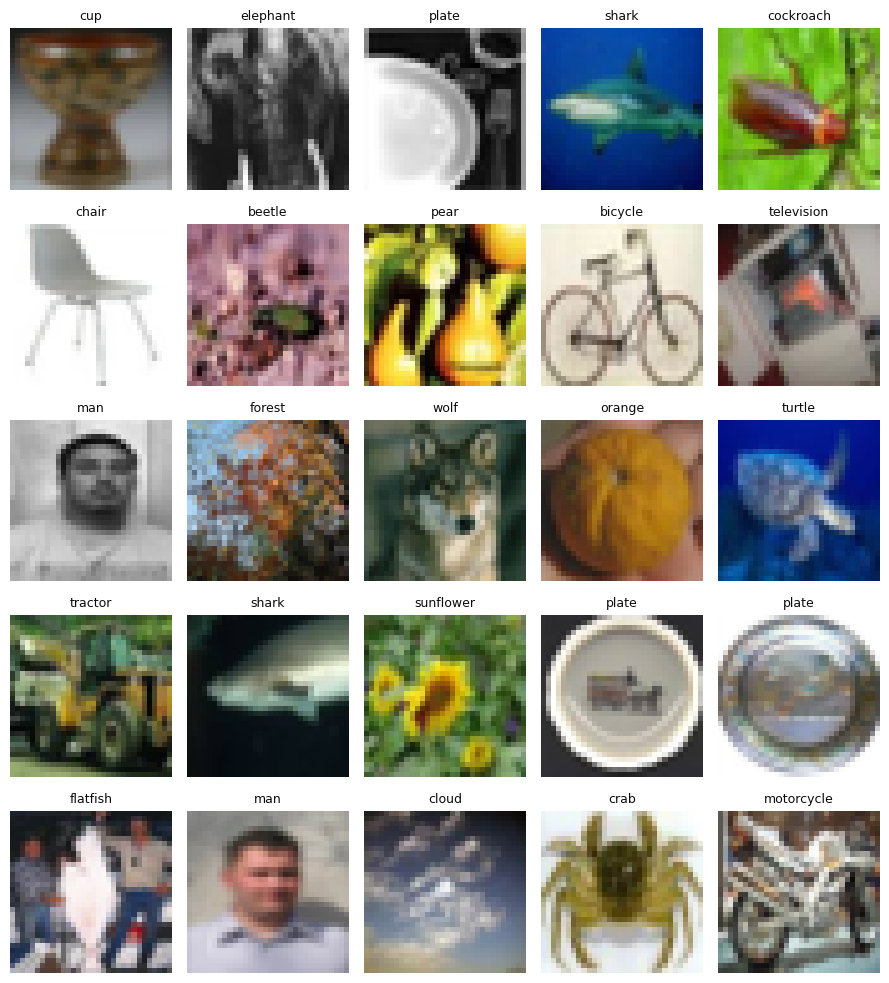

In [4]:
fig, axes = plt.subplots(5, 5, figsize=(9, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], interpolation="nearest")
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 4. 데이터 증강 (data augmentation)
fine 기준으로 클래스당 학습 이미지가 450장뿐이라, 모델이 이미지를 통째로 외워 버리기 쉽습니다(과적합).
그래서 학습할 때마다 이미지를 조금씩 바꿔서 보여 줍니다. 원본 예제와 같은 방식입니다.

- `RandomFlip("horizontal")`: 좌우를 무작위로 뒤집습니다.
- `RandomRotation(0.1)`: 최대 ±0.1바퀴(±36°) 무작위로 돌립니다.
- `RandomTranslation(0.1, 0.1)`: 상하좌우로 최대 10% 옮깁니다 (기본값은 끔).

증강은 학습 이미지에만 쓰고 검증·test 이미지에는 쓰지 않습니다. 아래는 같은 이미지 한 장에 증강을 8번 적용한 결과입니다.

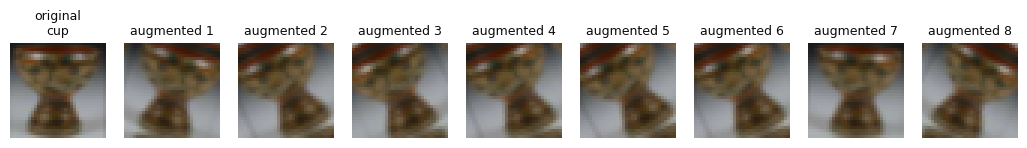

In [5]:
# 증강 층은 혼합 정밀도 설정과 상관없이 float32로 계산합니다 (CPU의 tf.data 안에서 실행되므로).
data_augmentation_layers = []
if "flip" in AUGMENT:
    data_augmentation_layers.append(layers.RandomFlip("horizontal", dtype="float32"))
if "rotation" in AUGMENT:
    data_augmentation_layers.append(layers.RandomRotation(0.1, dtype="float32"))
if "translation" in AUGMENT:
    data_augmentation_layers.append(layers.RandomTranslation(0.1, 0.1, dtype="float32"))


def data_augmentation(images):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images


if data_augmentation_layers:
    sample = np.repeat(x_train[:1].astype("float32"), 8, axis=0)
    augmented = np.clip(np.asarray(data_augmentation(sample)), 0, 255).astype("uint8")
    fig, axes = plt.subplots(1, 9, figsize=(13, 1.9))
    axes[0].imshow(x_train[0], interpolation="nearest")
    axes[0].set_title(f"original\n{CLASS_NAMES[y_train[0]]}", fontsize=9)
    for i, ax in enumerate(axes[1:]):
        ax.imshow(augmented[i], interpolation="nearest")
        ax.set_title(f"augmented {i + 1}", fontsize=9)
    for ax in axes:
        ax.axis("off")
    plt.show()
else:
    print("증강을 모두 껐습니다.")

## 5. 입력 파이프라인 (tf.data)
학습 이미지를 `BATCH_SIZE`장씩 묶음(batch)으로 나눠 모델에 넣습니다.

- 원본 예제가 고른 방식(Option 2)처럼 증강을 데이터 파이프라인 안에서 CPU로 처리합니다. GPU가 계산하는 동안 다음 묶음이 미리 준비됩니다(prefetch).
- 이미지는 0~255 정수(uint8)로 두었다가 묶음 단위로 실수(float32)로 바꿔 메모리를 아낍니다.
- 0~1로 맞추는 정규화(`Rescaling(1/255)`)는 모델 안에 있어서, 저장한 모델에는 0~255 사진을 그대로 넣으면 됩니다. 증강은 모델 밖에 있으므로 저장한 모델에는 들어가지 않습니다.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(x, y, shuffle, augment):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(min(len(x), 10_000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    if augment and data_augmentation_layers:
        ds = ds.map(lambda a, b: (data_augmentation(a), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(x_train, y_train, shuffle=True, augment=True)
val_ds = make_dataset(x_val, y_val, shuffle=False, augment=False)
STEPS = int(np.ceil(len(x_train) / BATCH_SIZE))
print(f"1 epoch = 학습 묶음 {STEPS}개 ({BATCH_SIZE}장씩) + 검증 묶음 {int(np.ceil(len(x_val) / BATCH_SIZE))}개")

1 epoch = 학습 묶음 352개 (128장씩) + 검증 묶음 40개


## 6. 모델 만들기
원본 예제의 `make_model`을 그대로 따르되, 180×180 이미지용 구조를 32×32에 맞게 줄였습니다. 모델은 이렇게 이어집니다.

1. **입구 블록**: 픽셀 값을 0~1로 바꾸고(`Rescaling`) 첫 합성곱(`Conv2D`)으로 기본 무늬를 찾습니다.
2. **잔차 블록 3개**: `SeparableConv2D` 두 번 + `MaxPooling2D`로 특징을 키우면서 이미지 크기를 절반씩 줄입니다 (32 → 16 → 8 → 4).
   블록 입력을 1×1 합성곱으로 크기를 맞춰 더하는 지름길(residual) 덕분에 층이 깊어도 학습이 잘 됩니다.
3. **출구**: `SeparableConv2D` → `GlobalAveragePooling2D`(위치별 특징의 평균) → `Dropout` → `Dense`(클래스 수)로 클래스별 점수(logit)를 냅니다. 점수에 softmax를 씌우면 확률이 됩니다.

| | 원본 예제 (Cats vs Dogs) | 이 노트북 (CIFAR-100) | 이유 |
|---|---|---|---|
| 입력 크기 | 180×180 | 32×32 | CIFAR-100 이미지 크기 |
| 첫 `Conv2D` | 128필터, stride 2 | 64필터, stride 1 | 작은 이미지를 처음부터 절반으로 줄이지 않음 |
| 블록 필터 수 | 256 → 512 → 728 | 128 → 256 → 512 | 이미지·데이터가 작아 모델도 줄임 |
| 마지막 `SeparableConv2D` | 1024 | 768 | 〃 |
| 출력 | 1개 (이진 분류) | 100개 또는 20개 (다중 분류) | 클래스 수 |
| 손실 함수 | `BinaryCrossentropy` | `SparseCategoricalCrossentropy` | 다중 분류 |
| BatchNorm momentum | 0.99 (기본값) | 0.9 | 짧게 학습해도 예측이 한 클래스로 몰리지 않음 |
| 데이터 | 폴더 이미지 (`image_dataset_from_directory`) | `keras.datasets.cifar100` | |
| 모델 저장 | epoch마다 저장 | val acc가 가장 높은 epoch만 저장 + early stopping | |

필터 수에는 모두 `WIDTH`를 곱합니다 (최소 16). 옵티마이저(Adam, 학습률 3e-4), 증강, Dropout 0.25, 25 epoch는 원본 예제와 같습니다.

Model: "xception_mini"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 32, 32, 3)       │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ rescaling (Rescaling)       │ (None, 32, 32, 3)       │              0 │ input_layer[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d (Conv2D)             │ (None, 32, 32, 64)      │          1,792 │ rescaling[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization         │ (None, 32, 32, 64)      │            256 │ conv2d[0][0]            │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation (Activation)     │ (None, 32, 32, 64)      │              0 │ batch_normalization[0]… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_1 (Activation)   │ (None, 32, 32, 64)      │              0 │ activation[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ separable_conv2d            │ (None, 32, 32, 128)     │          8,896 │ activation_1[0][0]      │
│ (SeparableConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_1       │ (None, 32, 32, 128)     │            512 │ separable_conv2d[0][0]  │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_2 (Activation)   │ (None, 32, 32, 128)     │              0 │ batch_normalization_1[… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ separable_conv2d_1          │ (None, 32, 32, 128)     │         17,664 │ activation_2[0][0]      │
│ (SeparableConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_2       │ (None, 32, 32, 128)     │            512 │ separable_conv2d_1[0][… │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ max_pooling2d               │ (None, 16, 16, 128)     │              0 │ batch_normalization_2[… │
│ (MaxPooling2D)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_1 (Conv2D)           │ (None, 16, 16, 128)     │          8,320 │ activation[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ add (Add)                   │ (None, 16, 16, 128)     │              0 │ max_pooling2d[0][0],    │
│                             │                         │                │ conv2d_1[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_3 (Activation)   │ (None, 16, 16, 128)     │              0 │ add[0][0]               │
├─────────────────────────────┼─────────────────────────┼────

 Total params: 1,190,692 (4.54 MB)

 Trainable params: 1,185,444 (4.52 MB)

 Non-trainable params: 5,248 (20.50 KB)

파라미터 1,190,692개


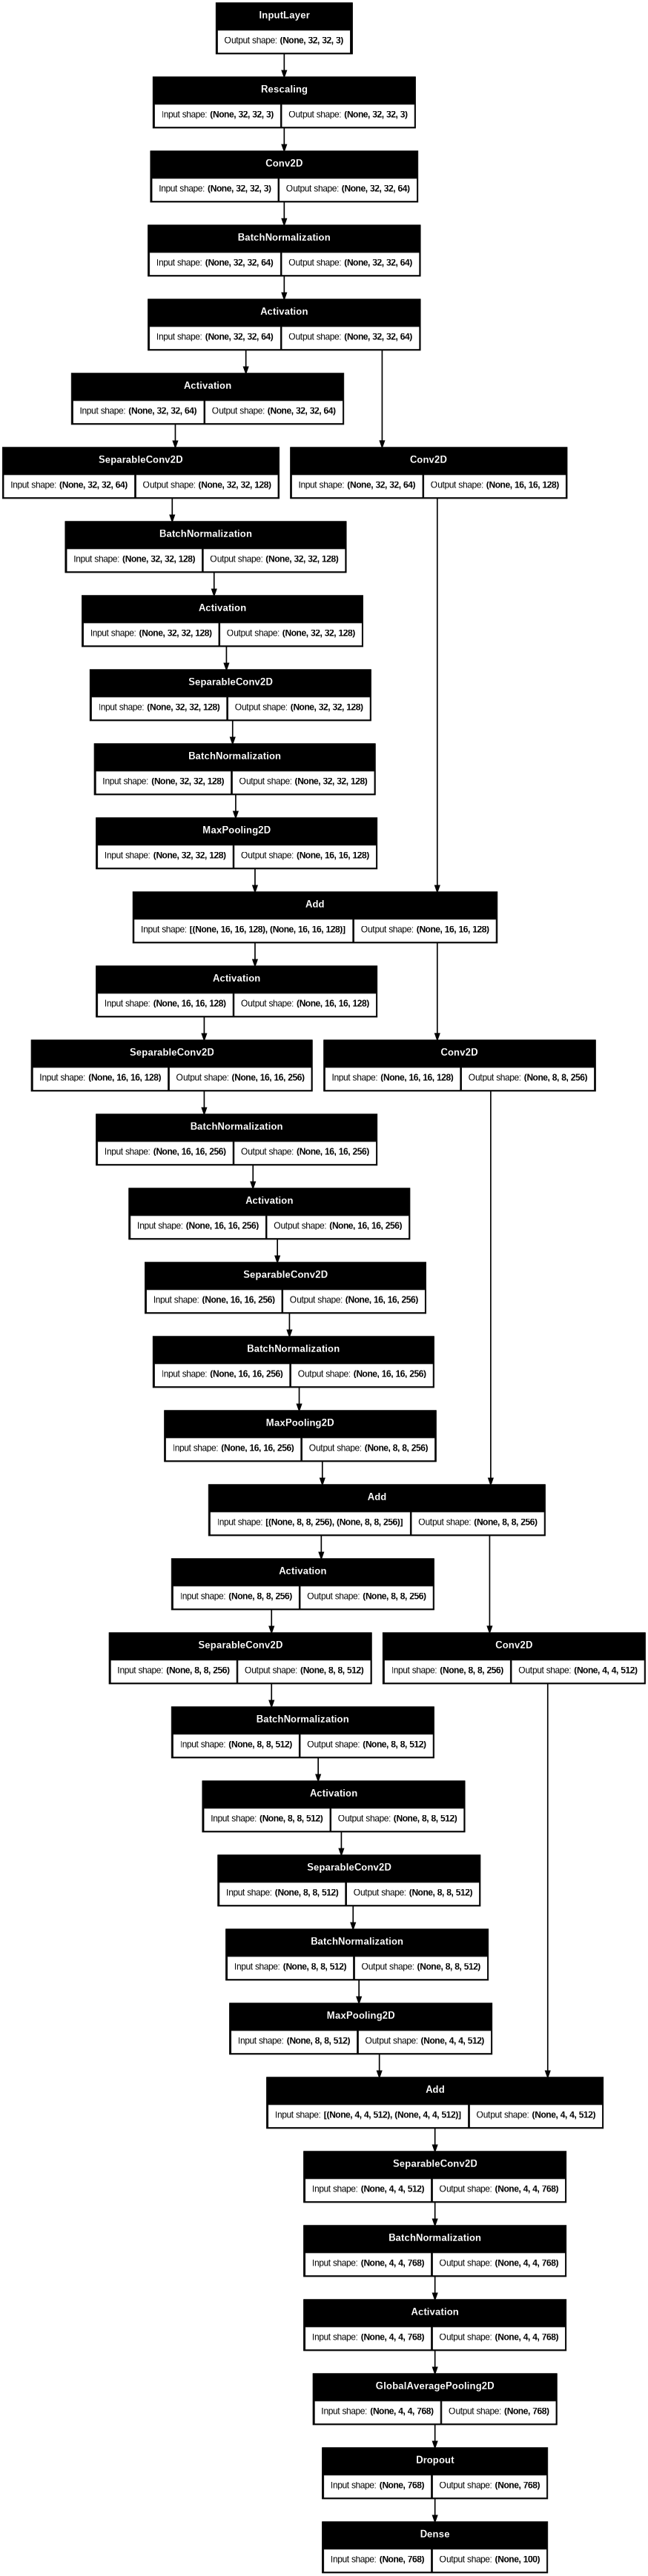

In [7]:
def make_model(input_shape, num_classes, width=1.0, dropout=0.25, bn_momentum=BN_MOMENTUM):
    def f(n):                       # 필터 수 × width (최소 16)
        return max(16, int(n * width))

    inputs = keras.Input(shape=input_shape)

    # Entry block (원본: Conv2D(128, 3, strides=2))
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = layers.Conv2D(f(64), 3, strides=1, padding="same")(x)
    x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.Activation("relu")(x)
    previous_block_activation = x   # residual 연결용

    for size in [f(128), f(256), f(512)]:          # 원본: [256, 512, 728]
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization(momentum=bn_momentum)(x)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization(momentum=bn_momentum)(x)
        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)
        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    x = layers.SeparableConv2D(f(768), 3, padding="same")(x)   # 원본: 1024
    x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.Activation("relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    # 원본은 이진 분류라 units=1. 여기서는 클래스 수만큼 점수(logit)를 냅니다.
    # 혼합 정밀도에서도 마지막 점수는 float32로 계산해 손실 값이 안정적이게 합니다.
    outputs = layers.Dense(num_classes, activation=None, dtype="float32")(x)
    return keras.Model(inputs, outputs, name="xception_mini")


model = make_model(INPUT_SHAPE, NUM_CLASSES, WIDTH, DROPOUT)
model.summary(line_length=100)
print(f"파라미터 {model.count_params():,}개")

# 원본 예제처럼 구조도를 그립니다 (pydot·graphviz가 없으면 건너뜁니다).
try:
    from IPython.display import Image as IPImage, display
    keras.utils.plot_model(model, to_file=str(OUT_DIR / "model.png"), show_shapes=True, dpi=60)
    display(IPImage(str(OUT_DIR / "model.png")))
except Exception as e:
    print(f"(구조도는 건너뜁니다: {type(e).__name__})")

## 7. 학습
진행 막대 오른쪽 숫자의 뜻은 이렇습니다.

| 이름 | 뜻 |
|---|---|
| `loss` | 학습 이미지에서 모델이 얼마나 틀렸는지 나타내는 오차입니다. 정답에 낮은 확률을 줄수록 커지며, 낮을수록 좋습니다. |
| `acc` | 학습 이미지를 맞힌 비율입니다 (증강된 이미지 기준). |
| `top5` | 정답이 모델의 상위 5개 후보 안에 든 비율입니다. 1순위만 보는 acc보다 항상 같거나 높습니다. |
| `val_loss` · `val_acc` · `val_top5` | 학습에 쓰지 않은 검증 이미지에서의 같은 값입니다. 처음 보는 이미지를 얼마나 잘 다루는지 보여 주며, **val_acc가 가장 중요한 지표**입니다. |

- epoch가 끝날 때마다 val_acc가 지금까지 중 가장 높으면 그 모델을 `best_model.keras`로 저장합니다.
- val_acc가 `PATIENCE`번 연속으로 나아지지 않으면 학습을 일찍 끝냅니다 (early stopping).
- 학습이 끝나면 가장 좋았던 epoch의 모델을 다시 불러와 아래 평가에 씁니다.

> 이 셀을 다시 실행하면 지금 모델에서 이어서 학습합니다. 처음부터 다시 하려면 §6부터 실행하세요.

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="acc"),
        keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5"),
    ],
)


class EpochTimer(keras.callbacks.Callback):
    """epoch마다 걸린 시간을 재고, 첫 epoch 뒤에 전체 예상 시간을 알려 줍니다."""

    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.t0)
        if len(self.times) == 1 and self.params.get("epochs", 1) > 1:
            total = self.times[0] * self.params["epochs"] / 60
            print(f"\n⏱ 첫 epoch {self.times[0]:.0f}초 → {self.params['epochs']} epoch 전체 약 {total:.0f}분 예상"
                  " (첫 epoch는 준비 시간이 들어가 조금 더 깁니다. early stopping이 걸리면 더 일찍 끝납니다.)\n")


CKPT = OUT_DIR / "best_model.keras"
timer = EpochTimer()
early_stop = (keras.callbacks.EarlyStopping(monitor="val_acc", mode="max", patience=PATIENCE, restore_best_weights=True)
              if PATIENCE > 0 else None)
callbacks = [
    keras.callbacks.ModelCheckpoint(str(CKPT), monitor="val_acc", mode="max", save_best_only=True),
    keras.callbacks.CSVLogger(str(OUT_DIR / "history.csv")),
    timer,
] + ([early_stop] if early_stop else [])

TRAIN_STARTED = datetime.now(SEOUL)
t0 = time.time()
history = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=callbacks,
                    shuffle=False)   # 섞기는 tf.data(§5)에서 이미 합니다.
TRAIN_TIME = time.time() - t0
TRAIN_FINISHED = datetime.now(SEOUL)

H = history.history
EPOCHS_DONE = len(H["loss"])
best_i = int(np.argmax(H["val_acc"]))
BEST = {"epoch": best_i + 1, **{k: float(H[k][best_i]) for k in ("val_acc", "val_top5", "val_loss", "acc", "loss")}}
EARLY_STOPPED = bool(early_stop is not None and early_stop.stopped_epoch > 0)

model = keras.saving.load_model(str(CKPT), compile=False)   # val_acc가 가장 높았던 epoch의 모델
print(f"\n학습 시간 {TRAIN_TIME / 60:.1f}분 (epoch당 평균 {np.mean(timer.times):.1f}초) · {EPOCHS_DONE}/{EPOCHS} epoch"
      + (" · early stopping" if EARLY_STOPPED else ""))
print(f"가장 좋은 epoch {BEST['epoch']}: val_acc {BEST['val_acc']:.2%} · val_top5 {BEST['val_top5']:.2%} · val_loss {BEST['val_loss']:.3f}")

Epoch 1/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - acc: 0.0991 - loss: 4.0063 - top5: 0.2807
⏱ 첫 epoch 117초 → 25 epoch 전체 약 49분 예상 (첫 epoch는 준비 시간이 들어가 조금 더 깁니다. early stopping이 걸리면 더 일찍 끝납니다.)

352/352 ━━━━━━━━━━━━━━━━━━━━ 117s 173ms/step - acc: 0.1456 - loss: 3.6631 - top5: 0.3772 - val_acc: 0.2298 - val_loss: 3.1293 - val_top5: 0.5244
Epoch 2/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - acc: 0.2561 - loss: 3.0009 - top5: 0.5561 - val_acc: 0.2942 - val_loss: 2.7889 - val_top5: 0.6034
Epoch 3/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - acc: 0.3192 - loss: 2.6725 - top5: 0.6364 - val_acc: 0.3374 - val_loss: 2.6524 - val_top5: 0.6502
Epoch 4/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - acc: 0.3660 - loss: 2.4396 - top5: 0.6898 - val_acc: 0.3700 - val_loss: 2.4699 - val_top5: 0.6810
Epoch 5/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - acc: 0.4040 - loss: 2.2643 - top5: 0.7223 - val_acc: 0.3980 - val_loss: 2.3542 - val_top5: 0.7024
Epoch 6/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 

## 8. 학습 곡선
가로축은 epoch(반복 횟수)입니다. **파란 실선은 학습 이미지, 주황 점선은 검증 이미지** 기준이고, 회색 세로 점선은 저장된(가장 좋은) epoch입니다.

- **loss 읽는 법**: 두 선이 함께 내려가면 잘 배우는 중입니다. loss는 계속 내려가는데 val_loss가 멈추거나 다시 올라가면, 학습 이미지를 외우기 시작한 것(과적합)입니다.
- **정확도 읽는 법**: 초반에는 증강·Dropout 때문에 학습 정확도가 검증보다 낮을 수 있는데 정상입니다. 학습이 진행되면 학습 정확도가 더 높아지며, 두 선의 간격이 계속 벌어지면 과적합 신호입니다. 검증 선은 epoch마다 조금씩 오르내리므로 전체 흐름을 보세요.
- 참고: M2 MacBook에서 같은 설정으로 25 epoch 학습했을 때 val_acc는 1 epoch 22.6%에서 24 epoch 56.9%(최고)까지 올랐습니다.

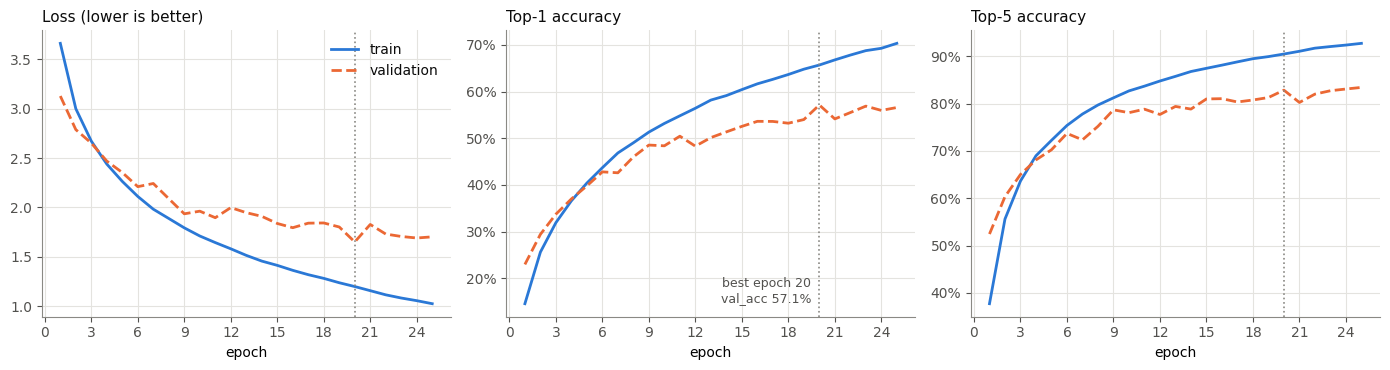

In [9]:
ep = np.arange(1, EPOCHS_DONE + 1)
marker = dict(marker="o", markersize=6) if EPOCHS_DONE <= 12 else {}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
panels = [("loss", "Loss (lower is better)", False),
          ("acc", "Top-1 accuracy", True),
          ("top5", "Top-5 accuracy", True)]
for ax, (key, title, pct) in zip(axes, panels):
    ax.plot(ep, H[key], color=C_TRAIN, label="train", **marker)
    ax.plot(ep, H["val_" + key], color=C_VAL, linestyle="--", label="validation", **marker)
    ax.axvline(BEST["epoch"], color=C_GRAY, linestyle=":", linewidth=1.2)
    ax.set_title(title, loc="left")
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].legend(loc="upper right")
# 저장된 epoch 표시: 회색 세로선 아래쪽에, 그래프 밖으로 나가지 않는 쪽에 적습니다.
right_half = BEST["epoch"] > (EPOCHS_DONE + 1) / 2
axes[1].annotate(f"best epoch {BEST['epoch']}\nval_acc {BEST['val_acc']:.1%}",
                 xy=(BEST["epoch"], 0.04), xycoords=("data", "axes fraction"),
                 xytext=(-6 if right_half else 6, 0), textcoords="offset points",
                 ha="right" if right_half else "left", va="bottom", fontsize=9, color=C_INK2)
fig.tight_layout()
fig.savefig(OUT_DIR / "learning_curves.png", dpi=120)
plt.show()

## 9. test 평가
test 이미지 10,000장은 학습에도, 가장 좋은 epoch를 고르는 데(검증)에도 쓰지 않았습니다. 그래서 여기 점수가 "처음 보는 이미지에서의 실력"에 가장 가깝습니다.

| 지표 | 뜻 |
|---|---|
| top-1 정확도 | 모델의 1순위 답이 정답인 비율입니다. 찍어서 맞힐 확률은 fine 1%, coarse 5%입니다. |
| 95% 신뢰구간 | test 10,000장도 표본이라 점수에 오차가 있습니다. 모델의 "진짜" 정확도가 이 범위 안에 있다고 95% 신뢰할 수 있다는 뜻입니다 (Wilson 방법). |
| top-5 정확도 | 정답이 상위 5개 후보 안에 든 비율입니다. |
| macro F1 | 클래스마다 F1(정밀도와 재현율의 조화평균)을 구해 평균한 값입니다. 일부 클래스만 잘 맞히면 낮아집니다. |
| ECE | 모델이 말한 확신도(예: 80%)와 실제 정답률의 평균 차이입니다. 0에 가까울수록 확신도를 믿을 수 있습니다. |

In [10]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support


def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


def wilson_ci(k, n, z=1.96):
    """이항 비율(정확도)의 Wilson 95% 신뢰구간."""
    p = k / n
    denom = 1 + z * z / n
    center = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return max(0.0, center - half), min(1.0, center + half)


def expected_calibration_error(conf, correct, n_bins=15):
    """확신도를 n_bins 구간으로 나눠 (구간별 정답률 - 평균 확신도)의 가중 평균을 구합니다."""
    edges = np.linspace(0, 1, n_bins + 1)
    bins, ece = [], 0.0
    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        mask = (conf > lo) & (conf <= hi) if i > 0 else (conf >= lo) & (conf <= hi)
        if mask.any():
            acc, avg_conf = correct[mask].mean(), conf[mask].mean()
            ece += mask.mean() * abs(acc - avg_conf)
            bins.append((lo, hi, int(mask.sum()), float(acc), float(avg_conf)))
    return float(ece), bins


logits = model.predict(x_test.astype("float32"), batch_size=256, verbose=0)
probs = softmax(np.asarray(logits, dtype=np.float64))
pred = probs.argmax(axis=1)
conf = probs.max(axis=1)
correct = pred == y_test
top5_correct = (np.argsort(-probs, axis=1)[:, :5] == y_test[:, None]).any(axis=1)

n = len(y_test)
k1, k5 = int(correct.sum()), int(top5_correct.sum())
labels = list(range(NUM_CLASSES))
prec, rec, f1, support = precision_recall_fscore_support(y_test, pred, labels=labels, zero_division=0)
cm = confusion_matrix(y_test, pred, labels=labels)
ece, rel_bins = expected_calibration_error(conf, correct.astype(float))
TEST = {
    "n": n, "top1": k1 / n, "top1_ci": wilson_ci(k1, n), "top5": k5 / n, "top5_ci": wilson_ci(k5, n),
    "loss": float(-np.mean(np.log(probs[np.arange(n), y_test] + 1e-12))),
    "macro_f1": float(np.mean(f1)), "ece": ece,
}

lo, hi = TEST["top1_ci"]
print(f"test {n:,}장 ({DATASET_ID})")
print(f"  top-1 정확도  {TEST['top1']:.2%}   (95% 신뢰구간 {lo:.2%} ~ {hi:.2%}, 찍어서 맞힐 확률 {1 / NUM_CLASSES:.0%})")
print(f"  top-5 정확도  {TEST['top5']:.2%}")
print(f"  macro F1      {TEST['macro_f1']:.3f}")
print(f"  ECE           {TEST['ece']:.3f}")
print(f"  loss          {TEST['loss']:.3f}")
print(f"  (참고: 검증 val_acc {BEST['val_acc']:.2%})")

test 10,000장 (cifar100_fine)
  top-1 정확도  57.23%   (95% 신뢰구간 56.26% ~ 58.20%, 찍어서 맞힐 확률 1%)
  top-5 정확도  83.59%
  macro F1      0.571
  ECE           0.059
  loss          1.622
  (참고: 검증 val_acc 57.12%)


## 10. 클래스별 분석
전체 정확도가 같아도 클래스마다 차이가 큽니다. 어떤 클래스가 쉽고 어려운지, 무엇과 헷갈리는지 봅니다.

- **막대그래프**: 클래스별 정확도(재현율, 그 클래스 test 이미지 중 맞힌 비율)가 가장 낮은/높은 10개입니다.
- **혼동 행렬(confusion matrix)**: 행은 정답, 열은 예측입니다. 각 행을 100%로 맞췄고 색이 진할수록 비율이 높습니다. 대각선이 진할수록 잘 맞힌 것이고, 대각선 밖의 진한 칸은 자주 헷갈리는 짝입니다.

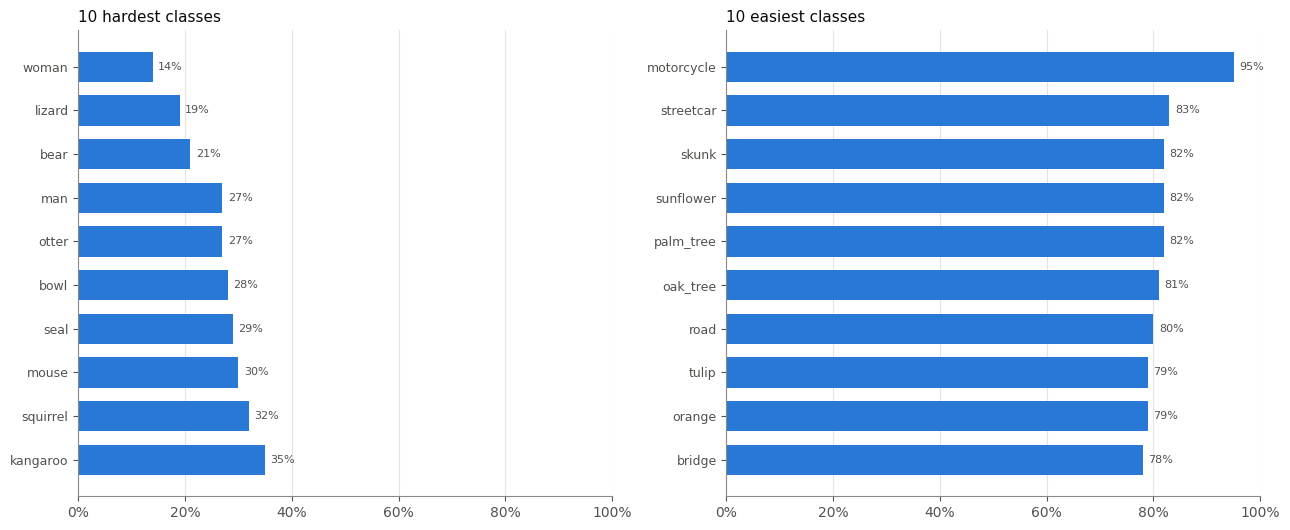

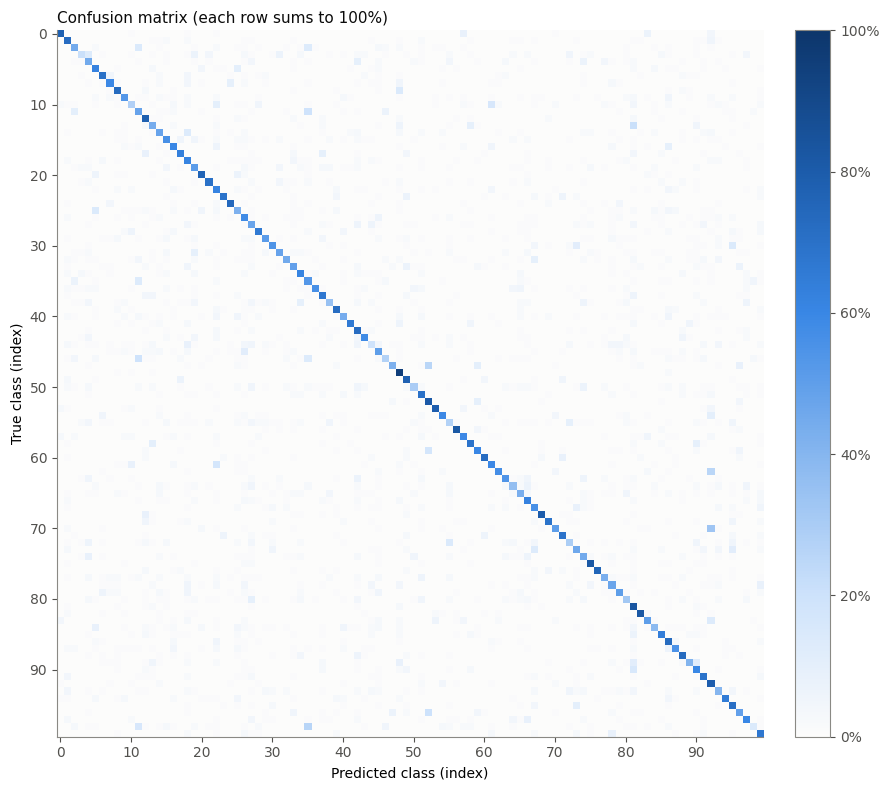

가장 자주 헷갈린 짝 (정답 → 예측, 그 클래스 test 이미지 중 비율)
                      rose → tulip                     33장 (33%)
                     woman → girl                      26장 (26%)
                maple_tree → oak_tree                  25장 (25%)
                     poppy → tulip                     25장 (25%)
                       bus → streetcar                 21장 (21%)
               willow_tree → oak_tree                  20장 (20%)
                       boy → girl                      19장 (19%)
                       man → boy                       19장 (19%)
                 pine_tree → oak_tree                  17장 (17%)
                     plate → clock                     17장 (17%)


In [11]:
order = np.argsort(rec)
k = min(10, NUM_CLASSES // 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.42 * k + 1.2))
for ax, idx, title in [(axes[0], order[:k], f"{k} hardest classes"), (axes[1], order[::-1][:k], f"{k} easiest classes")]:
    ax.barh(range(k), rec[idx], color=C_TRAIN, height=0.7)
    ax.set_yticks(range(k), [CLASS_NAMES[i] for i in idx], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")
    for j, v in enumerate(rec[idx]):
        ax.text(v + 0.01, j, f"{v:.0%}", va="center", fontsize=8, color=C_INK2)
fig.tight_layout()
plt.show()

norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
fig, ax = plt.subplots(figsize=(9, 8) if NUM_CLASSES > 30 else (9, 8.5))
im = ax.imshow(norm, cmap=BLUES, vmin=0, vmax=1)
ax.grid(False)
if NUM_CLASSES <= 30:
    ax.set_xticks(labels, CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(labels, CLASS_NAMES, fontsize=7)
else:
    ax.set_xticks(range(0, NUM_CLASSES, 10))
    ax.set_yticks(range(0, NUM_CLASSES, 10))
ax.set_xlabel("Predicted class (index)" if NUM_CLASSES > 30 else "Predicted class")
ax.set_ylabel("True class (index)" if NUM_CLASSES > 30 else "True class")
ax.set_title("Confusion matrix (each row sums to 100%)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, format=PercentFormatter(1.0, decimals=0))
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrix.png", dpi=120)
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
print("가장 자주 헷갈린 짝 (정답 → 예측, 그 클래스 test 이미지 중 비율)")
for flat in np.argsort(off, axis=None)[::-1][:10]:
    t, p = divmod(int(flat), NUM_CLASSES)
    print(f"  {CLASS_NAMES[t]:>24s} → {CLASS_NAMES[p]:<24s} {off[t, p]:>3d}장 ({off[t, p] / cm[t].sum():.0%})")

## 11. 틀린 예측과 확신도
- **위**: 모델이 크게 **확신하면서 틀린** test 이미지 24장입니다 (정답 → 예측, 확신도). 정답이 애매하거나 비슷하게 생긴 클래스가 많습니다.
- **아래: 신뢰도 그림(reliability diagram)**. 확신도 구간별 실제 정답률을 막대로 그립니다. 막대가 점선(완벽한 보정)보다 낮으면 모델이 실제보다 자신만만한 것이고, 높으면 조심스러운 것입니다.

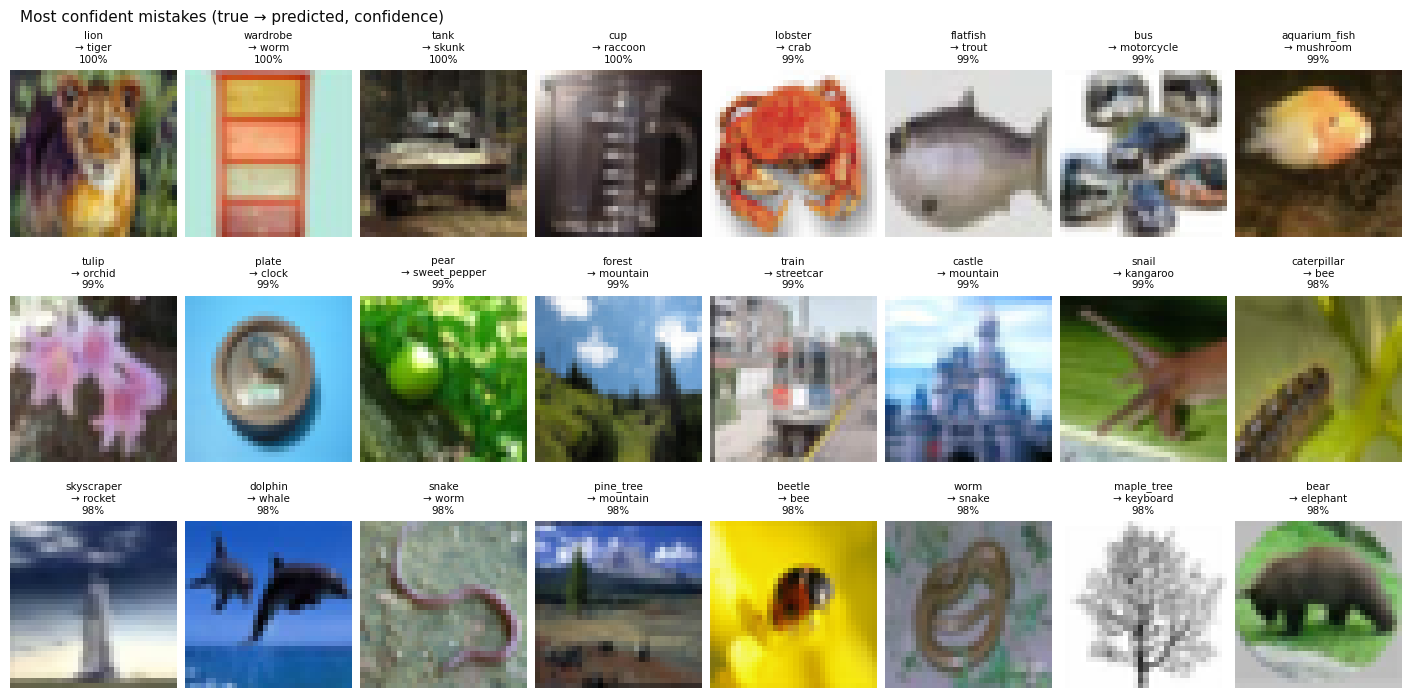

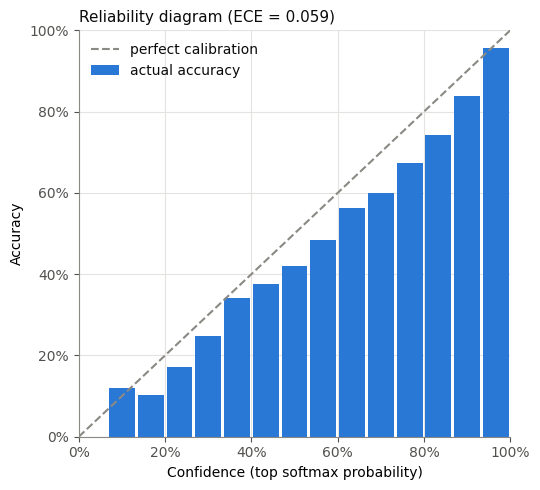

In [12]:
wrong = np.flatnonzero(~correct)
wrong = wrong[np.argsort(-conf[wrong])][:24]
fig, axes = plt.subplots(3, 8, figsize=(14, 7), layout="constrained")
for ax, i in zip(axes.flat, wrong):
    ax.imshow(x_test[i], interpolation="nearest")
    ax.set_title(f"{CLASS_NAMES[y_test[i]]}\n→ {CLASS_NAMES[pred[i]]}\n{conf[i]:.0%}", fontsize=7.5)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Most confident mistakes (true → predicted, confidence)", x=0.01, ha="left", fontsize=11)
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
width = rel_bins[0][1] - rel_bins[0][0]
ax.bar([(lo + hi) / 2 for lo, hi, *_ in rel_bins], [b[3] for b in rel_bins], width=width * 0.9,
       color=C_TRAIN, label="actual accuracy")
ax.plot([0, 1], [0, 1], linestyle="--", color=C_GRAY, linewidth=1.5, label="perfect calibration")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Confidence (top softmax probability)")
ax.set_ylabel("Accuracy")
ax.set_title(f"Reliability diagram (ECE = {TEST['ece']:.3f})", loc="left")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "reliability.png", dpi=120)
plt.show()

## 12. 이미지 한 장 예측하기
웹 UI와 같은 방식으로 이미지를 준비합니다: 가운데를 정사각형으로 자르고 32×32로 줄인 뒤(0~255 그대로) 모델에 넣습니다.
먼저 test 이미지 12장으로 확인하고(✓ 맞힘 / ✗ 틀림), 그다음 한 장의 상위 5개 후보를 봅니다.

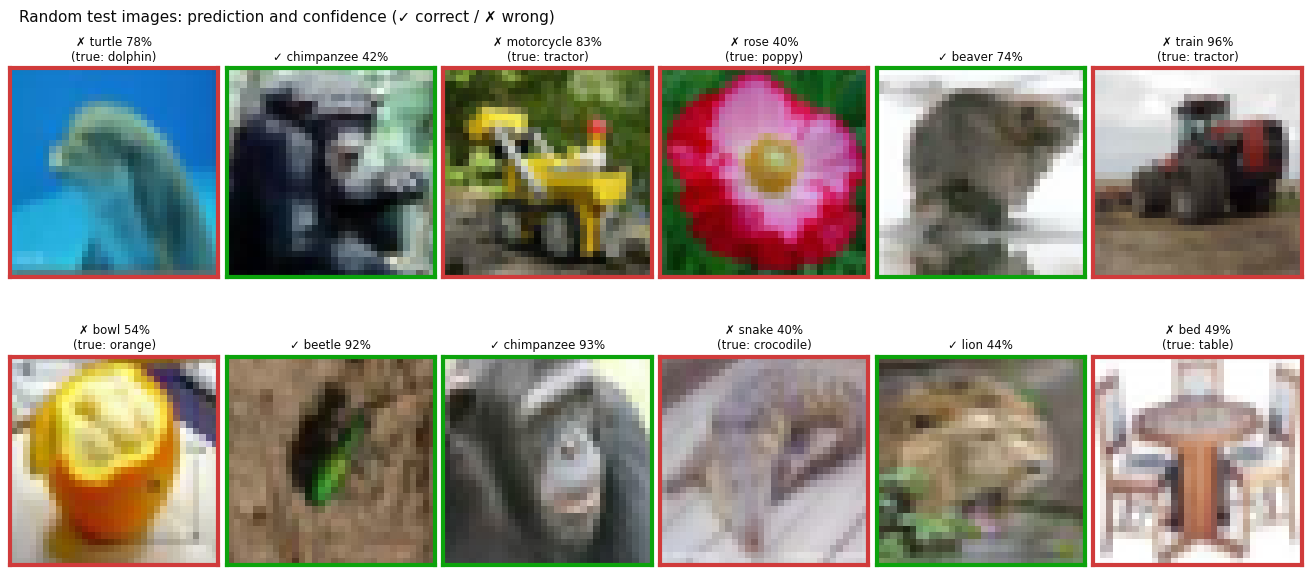

정답: dolphin


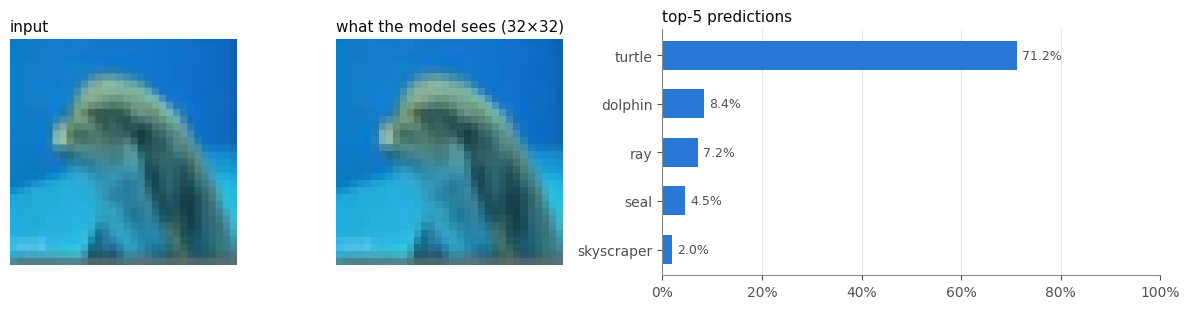

[('turtle', 0.7125),
 ('dolphin', 0.0837),
 ('ray', 0.0721),
 ('seal', 0.0451),
 ('skyscraper', 0.0201)]

In [13]:
from PIL import Image, ImageOps


def preprocess(img):
    """PIL 이미지 → (32, 32, 3) float32, 값 0~255 (Rescaling은 모델 안에 있습니다)."""
    img = ImageOps.fit(img.convert("RGB"), INPUT_SHAPE[:2], Image.Resampling.LANCZOS)  # 가운데 정사각 크롭 + 축소
    return np.asarray(img, dtype=np.float32)


def predict_image(img, top_k=5, show=True):
    x = preprocess(img)
    p = softmax(np.asarray(model.predict(x[None], verbose=0), dtype=np.float64))[0]
    top = np.argsort(-p)[:top_k]
    if show:
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1, 1, 2.2]})
        axes[0].imshow(img)
        axes[0].set_title("input", loc="left")
        axes[1].imshow(x.astype("uint8"), interpolation="nearest")
        axes[1].set_title("what the model sees (32×32)", loc="left")
        for ax in axes[:2]:
            ax.axis("off")
        axes[2].barh(range(top_k), p[top], color=C_TRAIN, height=0.6)
        axes[2].set_yticks(range(top_k), [CLASS_NAMES[i] for i in top])
        axes[2].invert_yaxis()
        axes[2].set_xlim(0, 1)
        axes[2].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        axes[2].grid(axis="y", visible=False)
        axes[2].set_title(f"top-{top_k} predictions", loc="left")
        for j, v in enumerate(p[top]):
            axes[2].text(v + 0.01, j, f"{v:.1%}", va="center", fontsize=9, color=C_INK2)
        fig.tight_layout()
        plt.show()
    return [(CLASS_NAMES[i], round(float(p[i]), 4)) for i in top]


rng = np.random.default_rng(SEED)
picks = rng.choice(len(x_test), 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 6), layout="constrained")
for ax, i in zip(axes.flat, picks):
    ok = pred[i] == y_test[i]
    ax.imshow(x_test[i], interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_color(C_GOOD if ok else C_BAD)
        s.set_linewidth(3)
    ax.set_title(f"{'✓' if ok else '✗'} {CLASS_NAMES[pred[i]]} {conf[i]:.0%}" + ("" if ok else f"\n(true: {CLASS_NAMES[y_test[i]]})"),
                 fontsize=8.5)
fig.suptitle("Random test images: prediction and confidence (✓ correct / ✗ wrong)", x=0.01, ha="left", fontsize=11)
plt.show()

i = int(picks[0])
print("정답:", CLASS_NAMES[y_test[i]])
predict_image(Image.fromarray(x_test[i]).resize((128, 128), Image.Resampling.NEAREST))

### 웹캠으로 찍어서 예측하기 (Colab 전용, 선택)
`USE_WEBCAM`을 켜고 **이 셀만** 실행하세요. 브라우저가 카메라 권한을 물으면 허용하고, 화면 아래 **📸 찍기** 버튼을 누르면 됩니다.
CIFAR-100에 있는 사물(사과, 의자, 컵, 시계 등)을 화면 가운데에 크게 비추면 맞힐 가능성이 높아집니다. 학습 이미지와 조명·배경이 달라서 test 정확도보다는 낮게 나오는 것이 보통입니다.

In [14]:
# @title 웹캠 사진 예측
USE_WEBCAM = False   # @param {type:"boolean"}

if not USE_WEBCAM:
    print("USE_WEBCAM을 켜고 이 셀을 실행하면 카메라가 열립니다.")
elif not IN_COLAB:
    print("이 셀은 Google Colab에서만 동작합니다.")
else:
    from base64 import b64decode
    from io import BytesIO
    from IPython.display import Javascript, display
    from google.colab.output import eval_js

    display(Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.cssText = 'display:block;max-width:480px;border-radius:8px';
      const button = document.createElement('button');
      button.textContent = '📸 찍기';
      button.style.cssText = 'font-size:16px;padding:6px 16px;margin:8px 0';
      div.appendChild(video);
      div.appendChild(button);
      document.body.appendChild(div);
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach((t) => t.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """))
    data_url = eval_js("takePhoto(0.9)")
    photo = Image.open(BytesIO(b64decode(data_url.split(",", 1)[1])))
    print(predict_image(photo))

USE_WEBCAM을 켜고 이 셀을 실행하면 카메라가 열립니다.


## 13. 저장·내려받기 (웹 UI로 가져가기)
학습한 모델을 로컬 웹 UI의 모델 폴더 형식(`model.keras`, `meta.json`, `history.csv`, `summary.txt`)으로 묶어 zip으로 내려받습니다.
혼합 정밀도로 학습했다면 같은 구조의 float32 모델에 가중치를 옮겨 저장하므로, CPU에서도 그대로 쓸 수 있습니다.

In [15]:
def width_tag(w):
    s = f"{float(w):g}"
    return s if "." in s else s + ".0"


# 1) float32 모델로 옮겨 저장 (혼합 정밀도 설정은 저장 후 원래대로 되돌립니다)
prev_policy = keras.mixed_precision.global_policy()
keras.mixed_precision.set_global_policy("float32")
export_model = make_model(INPUT_SHAPE, NUM_CLASSES, WIDTH, DROPOUT)
keras.mixed_precision.set_global_policy(prev_policy)
export_model.set_weights(model.get_weights())
check = np.argmax(export_model.predict(x_test[:1000].astype("float32"), batch_size=256, verbose=0), axis=1)
print(f"저장용 모델 확인: test 1,000장에서 원래 모델과 예측 일치 {np.mean(check == pred[:1000]):.1%}")

# 2) 웹 UI 모델 폴더 형식으로 묶기
wtag = width_tag(WIDTH)
MODEL_ID = f"{TRAIN_STARTED:%Y%m%d-%H%M%S}_xception_mini-w{wtag}_{DATASET_ID}"
bundle = OUT_DIR / "webui" / MODEL_ID
bundle.mkdir(parents=True, exist_ok=True)
export_model.save(str(bundle / "model.keras"))
shutil.copy(OUT_DIR / "history.csv", bundle / "history.csv")
from IPython.utils.capture import capture_output
summary_lines = []
with capture_output():   # 요약표는 화면에 다시 출력하지 않고 파일로만 남깁니다.
    export_model.summary(print_fn=lambda s, **kw: summary_lines.append(s), line_length=100)
(bundle / "summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")

where = "Google Colab" if IN_COLAB else "Jupyter"
meta = {
    "id": MODEL_ID,
    "name": f"xception_mini w{wtag} ({LABEL_MODE}) · {where}",
    "status": "ready",
    "dataset": DATASET_ID,
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "input_shape": list(INPUT_SHAPE),
    "arch": "xception_mini",
    "hparams": {"width": WIDTH, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LEARNING_RATE, "dropout": DROPOUT,
                "augment": AUGMENT, "val_split": VAL_SPLIT, "train_subset": TRAIN_SUBSET, "patience": PATIENCE, "seed": SEED},
    "arch_config": {"bn_momentum": BN_MOMENTUM, "mixed_precision": USE_MIXED_PRECISION},
    "data": {"train": len(x_train), "val": len(x_val)},
    "device": DEVICE,
    "train_env": {"env": "colab" if IN_COLAB else "jupyter", "platform": f"{platform.system()}-{platform.machine()}",
                  "python": platform.python_version(), "tensorflow": tf.__version__, "tensorflow_metal": None,
                  "keras": keras.__version__, "numpy": np.__version__},
    "job_id": None,
    "num_params": int(export_model.count_params()),
    "best": BEST,
    "epochs_completed": EPOCHS_DONE,
    "early_stopped": EARLY_STOPPED,
    "train_time_sec": round(TRAIN_TIME, 1),
    "avg_epoch_sec": round(float(np.mean(timer.times)), 2),
    "created_at": TRAIN_STARTED.isoformat(timespec="seconds"),
    "finished_at": TRAIN_FINISHED.isoformat(timespec="seconds"),
    "tags": ["colab"] if IN_COLAB else [],
    "memo": f"{where} 노트북에서 학습 · 노트북 test top-1 {TEST['top1']:.2%}",
}
(bundle / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
zip_path = shutil.make_archive(str(OUT_DIR / MODEL_ID), "zip", root_dir=bundle.parent, base_dir=MODEL_ID)
print(f"모델 ID: {MODEL_ID}")
print(f"zip: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")

# 3) 내려받기
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)   # 브라우저가 여러 파일 내려받기를 물으면 허용하세요.
if SAVE_TO_DRIVE and IN_COLAB:
    print(f"Google Drive에도 저장했습니다: {OUT_DIR}")

저장용 모델 확인: test 1,000장에서 원래 모델과 예측 일치 99.9%
모델 ID: 20261109-211959_xception_mini-w1.0_cifar100_fine
zip: /content/cifar100_cnn_outputs/20261109-211959_xception_mini-w1.0_cifar100_fine.zip (4.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 웹 UI로 가져가기
1. 내려받은 `<모델 ID>.zip`을 프로젝트 폴더의 `storage/models/` 안에 풉니다. 터미널에서는:
   ```bash
   unzip ~/Downloads/<모델 ID>.zip -d storage/models/
   ```
   `storage/models/<모델 ID>/model.keras`처럼 폴더 하나가 생기면 됩니다.
2. 웹 UI의 **모델** 화면을 새로 고치면 목록에 나타납니다. **평가** 화면에서 test 평가를, **웹캠 테스트** 화면에서 실시간 예측을 할 수 있습니다.

> 웹 UI는 Keras 3.15.1을 씁니다. §0에 출력된 Colab의 Keras 버전이 이보다 많이 새로워서 웹 UI가 모델을 불러오지 못하면, 맨 위에 `!pip install keras==3.15.1` 셀을 추가해 런타임을 다시 시작한 뒤 학습해 보세요.

### 참고
- 원본 예제: [Image classification from scratch](https://keras.io/examples/vision/image_classification_from_scratch/) (Keras)
- 데이터셋: [CIFAR100 small images classification dataset](https://keras.io/api/datasets/cifar100/) (Keras API) · 원본 [CIFAR-10/100](https://www.cs.toronto.edu/~kriz/cifar.html) (Krizhevsky, 2009)